# Drawing SPLINTER trees

`splinter.viz.plot_tree` draws a fitted tree with Graphviz and returns a `graphviz.Digraph`, which displays inline here. Edge labels follow how the tree routes rows: a value equal to a cutpoint goes to the right child, so `< t` | `≥ t` and `[a, b)`. A label such as `≤ 102.4` means the true cutpoint lies just above 102.4. See [Draw a tree](../README.md#draw-a-tree) for the drawing instructions. The same steps are in `examples/visualize.py`.

In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split

from splinter import SPLINTER, ShapeSPLINTER
from splinter.viz import plot_tree

## 1. Breast cancer with SPLINTER

Pass test rows to show how many reach each node; leaf colour shows how pure the leaf is on those rows.

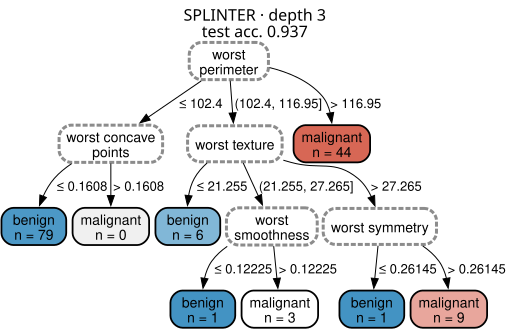

In [2]:
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target_names[data.target], stratify=data.target, random_state=42
)
settings = dict(max_depth=3, lookahead_depth=1, min_samples_leaf=5, lgbm_n_estimators=16)
model = SPLINTER(**settings).fit(X_train, y_train, feature_names=data.feature_names)
acc = model.score(X_test, y_test)
plot_tree(model, X_test, y_test, title=f"SPLINTER · depth {model.tree_depth()}\ntest acc. {acc:.3f}")

## 2. ShapeSPLINTER, detailed style

`style="detailed"` adds the split arity, row counts and class counts. `merge_leaves=True` merges sibling leaves that predict the same class; predictions do not change.

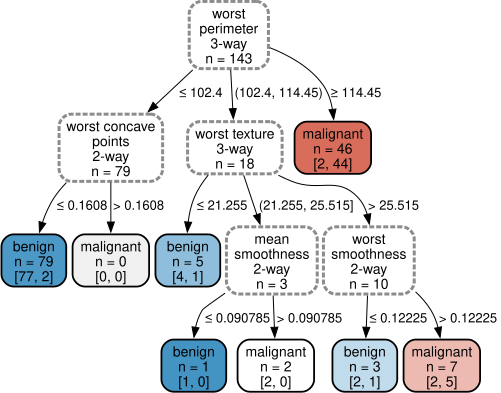

In [3]:
model = ShapeSPLINTER(**settings).fit(X_train, y_train, feature_names=data.feature_names)
plot_tree(model, X_test, y_test, style="detailed", merge_leaves=True)

## 3. A categorical feature

`plan` is coded 0..3. With `category_names`, the edges of a split on `plan` list the plans that take each branch. Customers on the basic or family plan churn in their first year.

In [4]:
PLANS = ["basic", "standard", "premium", "family"]


def churn_data(n=600, seed=0):
    """Plans 0..3 and tenure in months; basic/family plans churn early."""
    rng = np.random.default_rng(seed)
    plan, tenure = rng.integers(4, size=n), rng.integers(73, size=n)
    churn = np.isin(plan, [0, 3]) & (tenure < 12)
    churn ^= rng.random(n) < 0.05
    return np.column_stack([plan, tenure]).astype(float), np.where(churn, "churn", "stay")

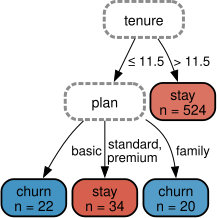

In [5]:
X, y = churn_data()
model = ShapeSPLINTER(max_depth=2).fit(X, y, feature_names=["plan", "tenure"])
plot_tree(model, X, y, category_names={"plan": PLANS})

## 4. Iris, three classes

Multiclass leaves use the Okabe-Ito colours.

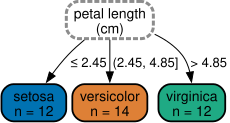

In [6]:
data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target_names[data.target], stratify=data.target, random_state=42
)
model = SPLINTER(max_depth=2).fit(X_train, y_train, feature_names=data.feature_names)
dot = plot_tree(model, X_test, y_test)
dot

## Saving a drawing

`render` writes `tree.pdf` (or `png`, `svg`) next to the notebook.

In [7]:
# dot.render("tree", format="pdf", cleanup=True)